In [1]:
from pathlib import Path

from skald import combine_runs
import seaborn as sns
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
import numpy as np

from experiments.visualizations import set_paper_style

set_paper_style()

In [2]:
topology_metrics = (
    combine_runs(
        Path(r"W:\EndlessWM\experiments\reports\static_complexity"),
        include_params=["data.name", "data.stream.data_fraction", "seed"],
    )
    .rename({"data.name": "dataset"})
    .filter(
        name="mAP",
        pattern="*",
        task=0,
        stream="present",
    )
    .with_columns(
        [pl.col("epoch").cast(pl.Int64), (pl.col("data.stream.data_fraction") * 100000).cast(pl.Int64).alias("№ samples")],
    )
)

topology_metrics

2026-08-25 10:00:30.988 | INFO     | skald:combine_runs:463 - 🔎 found 144 skald runs in W:\EndlessWM\experiments\reports\static_complexity.


Output()

name,value,stream,step,epoch,task,pattern,dataset,data.stream.data_fraction,seed,№ samples
str,f64,str,i64,i64,i64,str,str,f64,i32,i64
"""mAP""",0.2688,"""present""",null,0,0,"""*""","""III""",0.0025,42,250
"""mAP""",0.2738,"""present""",null,1,0,"""*""","""III""",0.0025,42,250
"""mAP""",0.2787,"""present""",null,2,0,"""*""","""III""",0.0025,42,250
"""mAP""",0.2706,"""present""",null,3,0,"""*""","""III""",0.0025,42,250
"""mAP""",0.2663,"""present""",null,4,0,"""*""","""III""",0.0025,42,250
…,…,…,…,…,…,…,…,…,…,…
"""mAP""",0.9948,"""present""",null,96,0,"""*""","""I""",1.0,44,100000
"""mAP""",0.9952,"""present""",null,97,0,"""*""","""I""",1.0,44,100000
"""mAP""",0.9967,"""present""",null,98,0,"""*""","""I""",1.0,44,100000


In [3]:
mixedwm38_metrics = (
    combine_runs(
        Path(r"W:\EndlessWM\experiments\reports\mixedwm38"),
        include_params=["data.name", "data.stream.data_fraction", "seed"],
    )
    .rename({"data.name": "dataset"})
    .filter(
        name="mAP",
        pattern="*",
        task=0,
        stream="present",
        dataset="MixedWM38",
    )
    .with_columns(
        [
            pl.col("epoch").cast(pl.Int64),
            pl.lit("topology_sample_sweep").alias("mixedwm38"),
            (pl.col("data.stream.data_fraction") * 0.8 * 38015).cast(pl.Int64).alias("№ samples"),
        ],
    )
)

mixedwm38_metrics

2026-08-25 10:03:51.789 | INFO     | skald:combine_runs:463 - 🔎 found 60 skald runs in W:\EndlessWM\experiments\reports\mixedwm38.


Output()

name,value,stream,step,epoch,task,pattern,dataset,data.stream.data_fraction,seed,mixedwm38,№ samples
str,f64,str,i64,i64,i64,str,str,f64,i32,str,i64
"""mAP""",0.2708,"""present""",null,0,0,"""*""","""MixedWM38""",0.033,42,"""topology_sample_sweep""",1003
"""mAP""",0.2738,"""present""",null,1,0,"""*""","""MixedWM38""",0.033,42,"""topology_sample_sweep""",1003
"""mAP""",0.2804,"""present""",null,2,0,"""*""","""MixedWM38""",0.033,42,"""topology_sample_sweep""",1003
"""mAP""",0.3088,"""present""",null,3,0,"""*""","""MixedWM38""",0.033,42,"""topology_sample_sweep""",1003
"""mAP""",0.3522,"""present""",null,4,0,"""*""","""MixedWM38""",0.033,42,"""topology_sample_sweep""",1003
…,…,…,…,…,…,…,…,…,…,…,…
"""mAP""",0.9648,"""present""",null,96,0,"""*""","""MixedWM38""",0.025,44,"""topology_sample_sweep""",760
"""mAP""",0.9606,"""present""",null,97,0,"""*""","""MixedWM38""",0.025,44,"""topology_sample_sweep""",760
"""mAP""",0.9606,"""present""",null,98,0,"""*""","""MixedWM38""",0.025,44,"""topology_sample_sweep""",760


In [4]:
metrics = pl.concat([topology_metrics, mixedwm38_metrics], how="diagonal_relaxed")

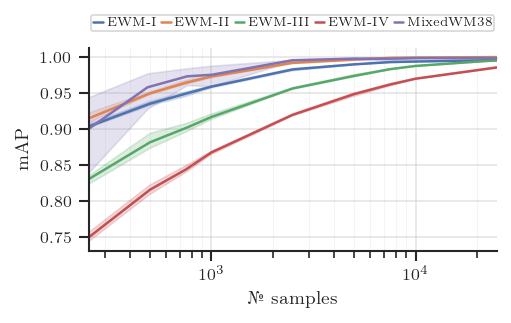

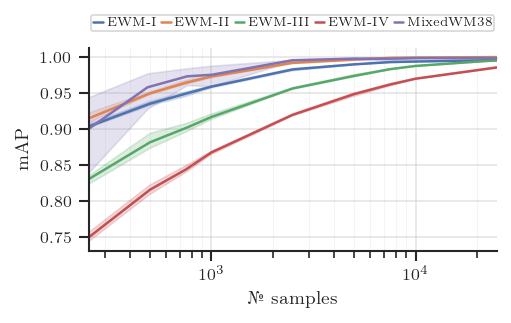

In [ ]:
set_paper_style()

_plot_df = metrics.filter(epoch=99).to_pandas()
_plot_df["dataset"] = _plot_df["dataset"].replace({"I": "EWM-I", "II": "EWM-II", "III": "EWM-III", "IV": "EWM-IV"})

dataset_order = [
    "EWM-I",
    "EWM-II",
    "EWM-III",
    "EWM-IV",
    "MixedWM38",
]

_fig, _ax = plt.subplots(figsize=(3.5, 2.25))

sns.lineplot(
    data=_plot_df,
    x="№ samples",
    y="value",
    hue="dataset",
    hue_order=dataset_order,
    ax=_ax,
)

_ax.set_xscale("log")
_ax.xaxis.set_major_locator(LogLocator(base=10.0))
_ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10)))

_ax.grid(True, which="major", alpha=0.5, linewidth=0.8)
_ax.grid(True, which="minor", alpha=0.2, linewidth=0.5)
_ax.set_xlim(250, 25000)

_ax.set_xlabel("№ samples")
_ax.set_ylabel("mAP")

sns.move_legend(
    _ax,
    "lower center",
    bbox_to_anchor=(0.43, 1.02),
    ncol=len(dataset_order),
    title=None,
    frameon=True,
    borderaxespad=1.0,
    borderpad=0.2,
    handlelength=0.85,
    handletextpad=0.35,
    columnspacing=0.5,
    labelspacing=0.2,
    fontsize=7,
)

_fig.tight_layout()

_fig

In [6]:
_output_dir = Path(r"..\..\reports\static_complexity")
_output_dir.mkdir(parents=True, exist_ok=True)

_fig.savefig(_output_dir / "static_complexity.png", bbox_inches="tight")
_fig.savefig(_output_dir / "static_complexity.pdf", bbox_inches="tight")

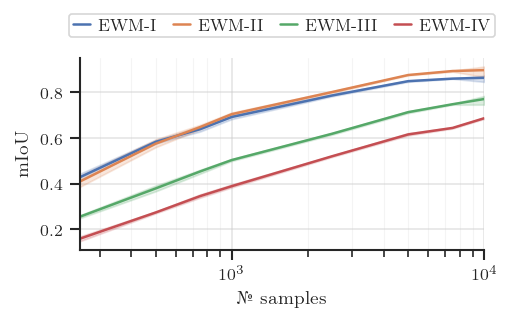

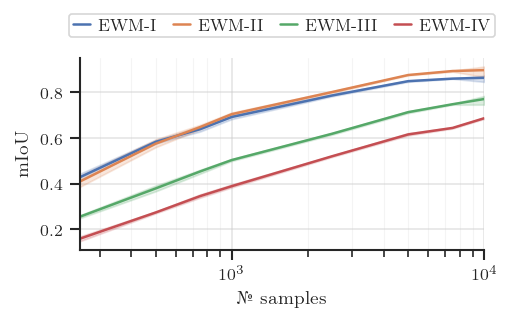

In [7]:
set_paper_style()

_segmentation_results = pl.read_json(Path(r"..\..\reports\semantic segmentation\sweep_results2.json"))
_segmentation_plot = _segmentation_results.select("dataset", "n_samples", "seed", "miou").to_pandas()
_segmentation_plot["dataset"] = _segmentation_plot["dataset"].replace({"I": "EWM-I", "II": "EWM-II", "III": "EWM-III", "IV": "EWM-IV"})
_segmentation_order = ["EWM-I", "EWM-II", "EWM-III", "EWM-IV"]

_segmentation_fig, _segmentation_ax = plt.subplots(figsize=(3.5, 2.25))
sns.lineplot(
    data=_segmentation_plot,
    x="n_samples",
    y="miou",
    hue="dataset",
    hue_order=_segmentation_order,
    ax=_segmentation_ax,
)

_segmentation_ax.set_xscale("log")
_segmentation_ax.xaxis.set_major_locator(LogLocator(base=10.0))
_segmentation_ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10)))
_segmentation_ax.grid(True, which="major", alpha=0.5, linewidth=0.8)
_segmentation_ax.grid(True, which="minor", alpha=0.2, linewidth=0.5)
_segmentation_ax.set_xlim(250, 10000)
_segmentation_ax.set_xlabel("№ samples")
_segmentation_ax.set_ylabel("mIoU")
sns.move_legend(
    _segmentation_ax,
    "lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(_segmentation_order),
    title=None,
    frameon=True,
    borderaxespad=1.0,
    borderpad=0.25,
    handlelength=1.0,
    handletextpad=0.5,
    columnspacing=1.0,
    labelspacing=0.2,
)
_segmentation_fig.tight_layout()
_segmentation_output_dir = Path(r"..\..\..\paper\figures\semantic_segmentation")
_segmentation_output_dir.mkdir(parents=True, exist_ok=True)
_segmentation_fig.savefig(_segmentation_output_dir / "semantic_segmentation.png", bbox_inches="tight")
_segmentation_fig.savefig(_segmentation_output_dir / "semantic_segmentation.pdf", bbox_inches="tight")
_segmentation_fig